In [10]:
# Load data
import os

import pandas as pd
from pymetropsis.plotting import plot_metropsis_group

# Load data
data_path = plot_metropsis_group.DATA_DIR / "raw/clean_metropsis_TCS-2e.csv"
data = pd.read_csv(data_path)

# Summarize data across participants
pid_df = plot_metropsis_group.summarize_contrastsens_by(
    data=data, group_vars=["participant_id", "block", "condition", "freq"]
)
pid_df.sort_values(by=["participant_id", "condition", "freq", "block"])

,participant_id,block,condition,freq,cs_mean,cs_sem
0,113,0.0,achromatic,2.0,0.220781,0.032605
6,113,1.0,achromatic,2.0,0.152577,0.018062
12,113,2.0,achromatic,2.0,0.149288,0.026235
18,113,3.0,achromatic,2.0,0.198611,0.032361
24,113,4.0,achromatic,2.0,0.151888,0.013178
...,...,...,...,...,...,...
767,213,6.0,red-green,8.0,0.712262,0.056352
773,213,7.0,red-green,8.0,0.774035,0.037776
779,213,8.0,red-green,8.0,0.851347,0.159629
785,213,9.0,red-green,8.0,1.103653,0.148851


# Empirical data

Below you can find each participant's empirical melatonin data and their melatonin fits. Fitting was sone with a sine-cosine parameterisation with two harmonics, i.e. the fundamental frequency, and the second harmonic (double frequency).
For identifying the 

/Users/hheinrichs/Documents/projects/civibe_psychophysics/notebooks


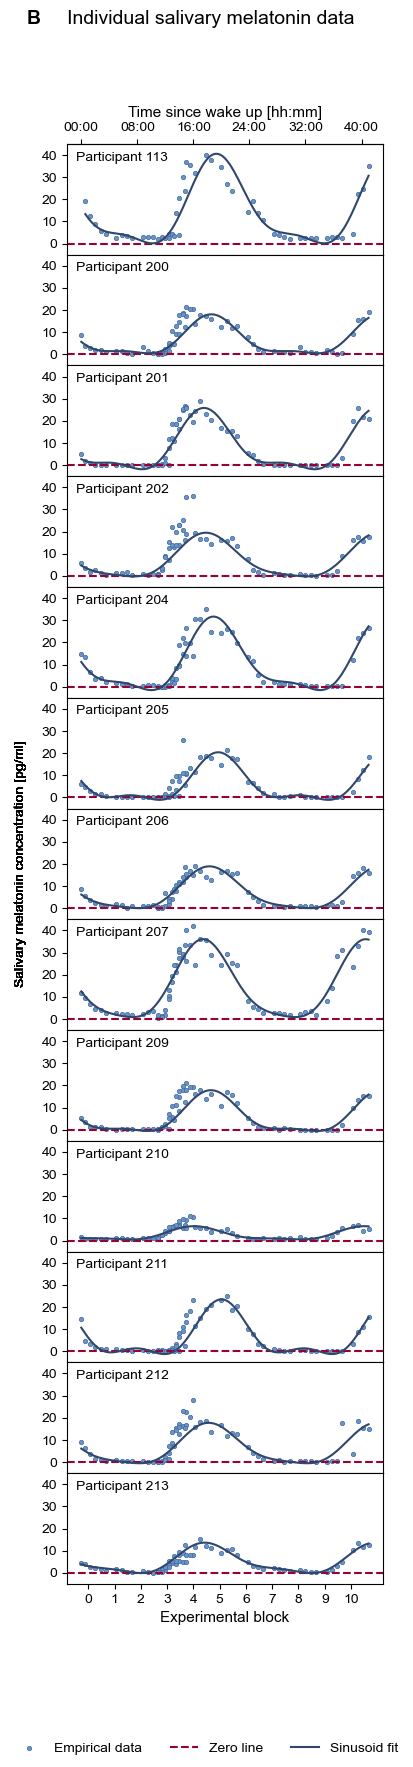

In [ ]:
import os
import pandas as pd

from pymetropsis.plotting import plot_metropsis_group

print(os.getcwd())
# Create individual melatonin plots - first participant subgroup
out_dir = "."
raw_path = plot_metropsis_group.DATA_DIR / "raw/clean_saliva_data.csv"
param_path = plot_metropsis_group.DATA_DIR / "derivatives/hormones/tau_harmonics/melatonin_circadian_parameters.csv"


melraw = pd.read_csv(raw_path)
melstat = pd.read_csv(param_path)
meldata = melraw.merge(melstat, on="participant_id")

# meldata = meldata.loc[(meldata["participant_id"] > 200)]
fig, _ = plot_metropsis_group.create_plot_individual_timecourse_melatonin(
    data=meldata, letter="B"
)
fig.set_figheight(18)
fig.set_figwidth(4)


# Simulation data

Data was simulated with R. There are different versions:

| Folder                     | Variable tau ? | Harmonics ? |   |
|----------------------------|----------------|-------------|---|
| `hormones_24_fundamenal`   | x              | x           |   |
| `hormones_tau_fundamental` | yes            | x           |   |
| `hormones_24_harmonics`    | x              | yes         |   |
| `hormones_tau_harmonics`   | yes            | yes         |   |

In [ ]:
from pymetropsis.simulate import simulate_hormones

Saved file with simulated parameters to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_fundamental/simulated_melatonin_input.csv
Saved file with simulated dataset to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_fundamental/simulated_melatonin_data.csv
Saved file with simulated parameters to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_tau_fundamental/simulated_melatonin_input.csv
Saved file with simulated dataset to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_tau_fundamental/simulated_melatonin_data.csv
Saved file with simulated parameters to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_harmonics/simulated_melatonin_input.csv
Saved file with simulated dataset to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_harmonics/simulated_melatonin_data.csv


,participant_id,session_id,tau,mesor,amplitude,phase_deg,phase,amplitude_2,phase_deg2,phase_2
0,201,FD,24.528193,2,8,0,0.000000,2.666667,0,0.000000
1,202,FD,23.548437,2,8,0,0.000000,2.666667,45,0.785398
2,203,FD,24.614687,2,8,35,0.610865,1.666667,0,0.000000
3,204,FD,24.959883,2,8,35,0.610865,1.666667,45,0.785398
4,205,FD,24.298891,2,9,180,3.141593,3.000000,0,0.000000


In [ ]:
# Simulate melatonin data
new_df_1, params_1 = simulate_hormones.main(n_participants=24, tau=24, harmonics=False)
new_df_2, params_2 = simulate_hormones.main(
    n_participants=24, tau=(23, 25), harmonics=False
)
new_df_3, params_3 = simulate_hormones.main(n_participants=24, tau=24, harmonics=True)
new_df_4, params_4 = simulate_hormones.main(
    n_participants=24, tau=(23, 25), harmonics=True
)

Saved file with simulated parameters to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_fundamental/simulated_melatonin_input.csv
Saved file with simulated dataset to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_fundamental/simulated_melatonin_data.csv
Saved file with simulated parameters to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_tau_fundamental/simulated_melatonin_input.csv
Saved file with simulated dataset to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_tau_fundamental/simulated_melatonin_data.csv
Saved file with simulated parameters to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_harmonics/simulated_melatonin_input.csv
Saved file with simulated dataset to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_24_harmonics/simulated_melatonin_data.csv


In [12]:
# Print first rows of most realistic simulated data
print("Dataset with simulated raw data:", new_df_4.head())
print("Input parameters of the simulation:", params_4.head())

Dataset with simulated raw data:    timestamp_number  hours_after_wakeup   standard_datetime  participant_id  \
0                 0            0.000000 2024-01-01 07:00:00             201   
1                 1            0.583333 2024-01-01 07:35:00             201   
2                 2            1.250000 2024-01-01 08:15:00             201   
3                 3            2.000000 2024-01-01 09:00:00             201   
4                 4            2.750000 2024-01-01 09:45:00             201   

   melatonin_concentration session_id  
0                12.666667         FD  
1                12.439508         FD  
2                11.644114         FD  
3                10.150507         FD  
4                 8.176248         FD  
Input parameters of the simulation:    participant_id session_id        tau  mesor  amplitude  phase_deg  \
0             201         FD  23.428726      2          8          0   
1             202         FD  24.504390      2          8          0   


In [ ]:
raw_path = "/Users/hheinrichs/Documents/projects/civibe_psychophysics/data/simulation/hormones_tau_harmonics/simulated_melatonin_data.csv"
param_path = "/Users/hheinrichs/Documents/projects/civibe_psychophysics/data/derivatives/simulation/hormones_tau_harmonics/melatonin_circadian_parameters.csv"

raw_data = pd.read_csv(raw_path)
param_df = pd.read_csv(param_path)

param_df = param_df[param_df["participant_id"] < 214].copy()